# Which method wins on the thirteen weeks it never saw?

**Week 4, Friday, chapter 2 of 3.** Chapter 1 showed that festival-aligned with
drift beats naive and SWLY for one week when the festival moves. Chapter 2 scores
every method across thirteen weeks the model has never seen (a hold-out), to see
which method is reliable across a window the plan has to cover.

**Who needs the answer.** The FC planner, who has to pick one forecast and defend
it; and the vendor's sponsor, whose model fits every training week within 2
percent and promises 22 percent for the festive window.

**The questions on the way.**

1. What is a hold-out, and how many weeks does the planner hide?
2. How does each method's forecast on the hold-out compare to the actual?
3. What is MAE, and why in shipments rather than in percent?
4. Which method wins, and by how much?

A note on the hold-out: the spine's "22 June to 21 September 2026" is 14 Mondays;
the 13 Mondays ending Mon 21 Sep 2026 begin Mon 29 Jun 2026. The generator and
this notebook use the 13-Monday window.

**Setup.** Load the shared helper and read the three case tables.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd

shipments = pd.read_csv(kit.data_dir() / "C2_W04_D05_weekly_shipments_STUDENT.csv")
shipments["week_start"] = pd.to_datetime(shipments["week_start"])
vendor = pd.read_csv(kit.data_dir() / "C2_W04_D05_vendor_forecast_STUDENT.csv")
vendor["week_start"] = pd.to_datetime(vendor["week_start"])
calendar = pd.read_csv(kit.data_dir() / "C2_W04_D05_calendar_STUDENT.csv")
calendar["week_start"] = pd.to_datetime(calendar["week_start"])
print(f"104 weeks of shipments, Mon {shipments['week_start'].min().date()} to Mon {shipments['week_start'].max().date()}")
print(f"{len(vendor)} vendor rows (fitted and forecast)")

104 weeks of shipments, Mon 2024-09-30 to Mon 2026-09-21
114 vendor rows (fitted and forecast)


The chapter runs in five steps.

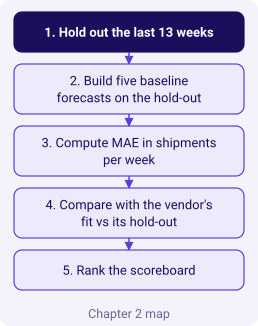

In [2]:
# MAP: the five questions the chapter answers.
kit.ladder(["Hold out the last 13 weeks",
            "Build five baseline forecasts on the hold-out",
            "Compute MAE in shipments per week",
            "Compare with the vendor's fit vs its hold-out",
            "Rank the scoreboard"], lit=0,
           title="Chapter 2 map")

## What is the hold-out, and which weeks does it cover?

The hold-out is the last thirteen Mondays of history. Nothing fitted on the
training weeks is allowed to see the hold-out weeks' shipments; every method's
forecast on the hold-out is scored against the actual.

**Predict before you run.** Which weeks do you expect to hide?

a) The last four weeks of history (26 Aug 2026 to 21 Sep 2026).
b) The last thirteen weeks of history (29 Jun 2026 to 21 Sep 2026).
c) The thirteen weeks before the 2025 festive peak (29 Sep 2025 to 15 Dec 2025).
d) A random thirteen weeks from across the 104.

In [3]:
HOLDOUT_START_IDX = 91  # zero-based; week 92 in 1-based
holdout = shipments.iloc[HOLDOUT_START_IDX:].reset_index(drop=True)
training = shipments.iloc[:HOLDOUT_START_IDX].reset_index(drop=True)
print(f"Training weeks: {len(training)}  ({training['week_start'].min().date()} to {training['week_start'].max().date()})")
print(f"Hold-out weeks: {len(holdout)}  ({holdout['week_start'].min().date()} to {holdout['week_start'].max().date()})")

Training weeks: 91  (2024-09-30 to 2026-06-22)
Hold-out weeks: 13  (2026-06-29 to 2026-09-21)


**What happened.** The answer is (b): the hold-out is the last 13 weeks of
history, because the plan has to forecast about 8 weeks ahead and the hold-out
should be at least as long as the horizon. A shorter hold-out (option a) rewards
a method that was lucky on the one week after training.

In [4]:
# Build each baseline's forecast for the 13 hold-out weeks.
s = shipments["shipments"].astype(float).tolist()

naive = [s[i - 1] for i in range(HOLDOUT_START_IDX, len(s))]
train_vals = s[:HOLDOUT_START_IDX]
mean_change = (train_vals[-1] - train_vals[0]) / (len(train_vals) - 1)
drift = [s[i - 1] + mean_change for i in range(HOLDOUT_START_IDX, len(s))]
swly = [s[i - 52] for i in range(HOLDOUT_START_IDX, len(s))]
finance = [s[i - 52] * 1.04 for i in range(HOLDOUT_START_IDX, len(s))]
# Festival-aligned with drift: no festive weeks sit in this hold-out, so this reduces
# to same-week-last-year plus a 4 percent growth bump (equal to finance's rule here).
fa_drift = finance[:]

actual = s[HOLDOUT_START_IDX:]
print(f"First actual (29 Jun 2026): {int(actual[0]):,}")
print(f"Last actual  (21 Sep 2026): {int(actual[-1]):,}")

First actual (29 Jun 2026): 232,100
Last actual  (21 Sep 2026): 241,600


## What is MAE, and why in shipments?

**Mean absolute error** is the average of the absolute differences between forecast
and actual, across the hold-out. We measure it in shipments rather than percent so
we can multiply by the per-shipment cost to get rupees.

In [5]:
def mae(forecast, actual):
    return sum(abs(f - a) for f, a in zip(forecast, actual)) / len(actual)

mae_naive = mae(naive, actual)
mae_drift = mae(drift, actual)
mae_swly = mae(swly, actual)
mae_fa = mae(fa_drift, actual)
mae_finance = mae(finance, actual)

vendor_hold = vendor[(vendor["week_start"] >= holdout["week_start"].iloc[0])
                    & (vendor["week_start"] <= holdout["week_start"].iloc[-1])]
vendor_vals = vendor_hold["vendor_shipments"].astype(float).tolist()
mae_vendor = mae(vendor_vals, actual)

print(f"Naive:                 MAE = {mae_naive:,.0f}")
print(f"Drift:                 MAE = {mae_drift:,.0f}")
print(f"Same-week-last-year:   MAE = {mae_swly:,.0f}")
print(f"Festival-aligned +4%:  MAE = {mae_fa:,.0f}")
print(f"Finance (SWLY + 4%):   MAE = {mae_finance:,.0f}")
print(f"Vendor curve:          MAE = {mae_vendor:,.0f}")

Naive:                 MAE = 22,046
Drift:                 MAE = 22,035
Same-week-last-year:   MAE = 9,346
Festival-aligned +4%:  MAE = 5,674
Finance (SWLY + 4%):   MAE = 5,674
Vendor curve:          MAE = 16,985


**Predict before you run (the trap).** The vendor's model fits every training
week within 2 percent of the actual. Which of these do you expect?

a) The vendor's hold-out MAE is also within 2 percent (its fit is reliable).
b) The vendor's hold-out MAE is 50 percent above festival-aligned's.
c) The vendor's hold-out MAE is at least 200 percent above festival-aligned's.
d) The vendor's hold-out MAE is better than SWLY's.

In [6]:
# The vendor's fit on the training weeks.
vendor_train = vendor[vendor["week_start"] <= training["week_start"].iloc[-1]]
train_merged = training.merge(vendor_train, on="week_start")
train_merged["pct_off"] = (train_merged["vendor_shipments"] - train_merged["shipments"]).abs() / train_merged["shipments"]
max_pct = train_merged["pct_off"].max()
mean_pct = train_merged["pct_off"].mean()
print(f"Vendor training fit:")
print(f"  mean abs deviation = {mean_pct * 100:.2f} percent of actual")
print(f"  max abs deviation  = {max_pct * 100:.2f} percent of actual")
print()
pct_above = (mae_vendor - mae_fa) / mae_fa * 100
print(f"Vendor hold-out MAE is {pct_above:.1f} percent above the festival-aligned baseline's")

Vendor training fit:
  mean abs deviation = 0.63 percent of actual
  max abs deviation  = 1.61 percent of actual

Vendor hold-out MAE is 199.3 percent above the festival-aligned baseline's


**What happened.** The answer is (c). The vendor fits every training week within
2 percent and misses the hold-out by about 200 percent above the festival-aligned
baseline's error. This is the gap between **fit** and **forecast**: a model that
memorised the past is not a model that generalises to weeks it has not seen.

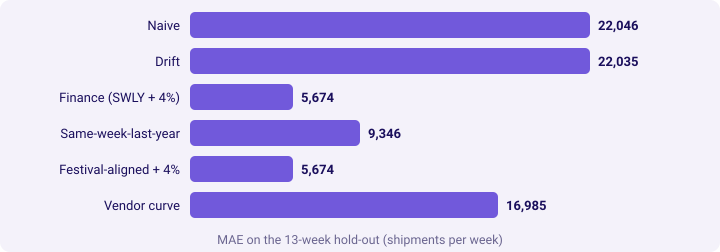

In [7]:
# The scoreboard as a horizontal bar.
kit.bars([("Naive", int(round(mae_naive))),
          ("Drift", int(round(mae_drift))),
          ("Finance (SWLY + 4%)", int(round(mae_finance))),
          ("Same-week-last-year", int(round(mae_swly))),
          ("Festival-aligned + 4%", int(round(mae_fa))),
          ("Vendor curve", int(round(mae_vendor)))],
         title="MAE on the 13-week hold-out (shipments per week)")
kit.check("vendor hold-out MAE is at least 1.3x festival-aligned", mae_vendor >= mae_fa * 1.3)
kit.check("vendor fits every training week within 2 percent", max_pct <= 0.02)
kit.check("naive loses to SWLY on this hold-out", mae_naive > mae_swly)

## Which direction is each method wrong in?

An MAE of 17,000 is not one number: 13 over-forecasts in a row cost idle
packer-shifts, and 13 under-forecasts in a row cost late shipments. The vendor's
pattern is systematic over-forecasting, which costs money every week.

In [8]:
def direction(forecast, actual, name):
    over = sum(1 for f, a in zip(forecast, actual) if f > a)
    under = sum(1 for f, a in zip(forecast, actual) if f < a)
    total_bias = sum(f - a for f, a in zip(forecast, actual)) / len(actual)
    print(f"{name:25s}: {over} over, {under} under, average miss {total_bias:+,.0f} shipments per week")

direction(naive, actual, "Naive")
direction(swly, actual, "Same-week-last-year")
direction(finance, actual, "Finance (SWLY + 4%)")
direction(vendor_vals, actual, "Vendor curve")

Naive                    : 6 over, 7 under, average miss -2,477 shipments per week
Same-week-last-year      : 1 over, 12 under, average miss -8,408 shipments per week
Finance (SWLY + 4%)      : 6 over, 7 under, average miss +42 shipments per week
Vendor curve             : 13 over, 0 under, average miss +16,985 shipments per week


**Your turn.** In the cell below, read the direction counts and write one sentence
that explains why finance (SWLY + 4 percent) lands closer than SWLY on this
hold-out, even though they only differ by a flat 4 percent bump.

**A second route to the ranking.** The MAE as computed above should match the
average miss we would get by summing absolute errors across the thirteen weeks
and dividing by thirteen. The next cell asserts the two routes agree.

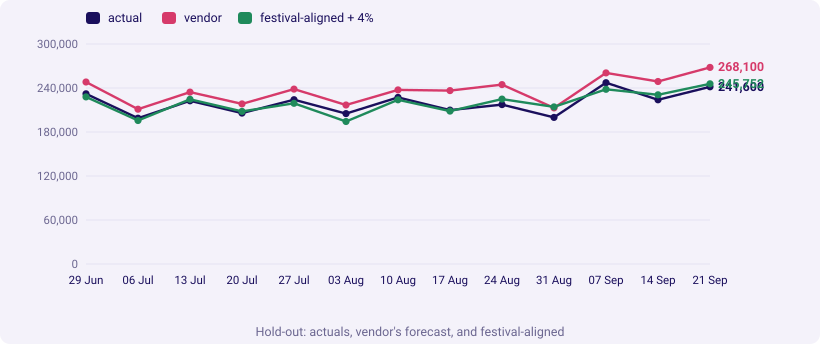

In [9]:
import statistics

mae_second = statistics.mean(abs(f - a) for f, a in zip(fa_drift, actual))
kit.check("festival-aligned MAE agrees between the two routes",
          abs(mae_second - mae_fa) < 1)
# SUM: the hold-out series with the vendor's and the chosen baseline's forecasts.
kit.line(labels=[d.strftime("%d %b") for d in holdout["week_start"]],
         series=[("actual", [int(a) for a in actual], "lit"),
                 ("vendor", [int(v) for v in vendor_vals], "bad"),
                 ("festival-aligned + 4%", [int(f) for f in fa_drift], "good")],
         title="Hold-out: actuals, vendor's forecast, and festival-aligned", width=820)
kit.check_summary()

## What the chapter earned, in one sentence

A forecast earns the plan only after it beats a naive baseline on weeks it has
not seen, and the baseline for a seasonal business is same-week-last-year or its
festival-aligned twin. Fit on past weeks is not forecast.

Chapter 3 turns the chosen forecast into a packer-shift plan with its error bar in rupees.